# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** - **Устройство:** свой ноутбук, NVIDIA GeForce RTX 4060 Laptop GPU (8 GB), Windows 11; torch 2.11.0+cu126, transformers 5.22.1, datasets 5.1.0, seqeval 1.2.2. Финальный прогон - Restart & Run All с `FAST_MODE = False`.
- **Модель:** [`google-bert/bert-base-cased`](https://huggingface.co/google-bert/bert-base-cased), revision `cd5ef92a9fb2f889e972770a36d4ed042daf221e`, лицензия Apache-2.0.
- **Датасет:** CoNLL-2003 (английский, новости Reuters), [`eriktks/conll2003`](https://huggingface.co/datasets/eriktks/conll2003), ветка `refs/convert/parquet`. В карточке лицензия `other`: разметка CoNLL-2003 свободна для исследований, тексты Reuters RCV1 доступны по исследовательскому соглашению Reuters/NIST, т.е. только некоммерческое исследовательское использование.
- **Бонусы:** 6.3 (устойчивость к сдвигу), 6.5 (порог уверенности спана). 6.1, 6.2, 6.4 не делались.
- **Источники:** документация HF «Token classification» (https://huggingface.co/docs/transformers/tasks/token_classification) - схема `Trainer` + `DataCollatorForTokenClassification`; документация `seqeval`. Код написан с помощью ИИ-ассистента (Claude), результаты и выводы проверены по выводу ноутбука.
- **Нерешенные задачи:** нет (все обязательные задачи 1-5 выполнены).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1122 22:32:11.752000 29108 torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


torch 2.11.0+cu126, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda NVIDIA GeForce RTX 4060 Laptop GPU


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'google-bert/bert-base-cased'   # английский BERT-base, cased: регистр - важный признак имен собственных
REVISION = 'cd5ef92a9fb2f889e972770a36d4ed042daf221e'   # HfApi().model_info(MODEL_ID).sha на 22.11.2026
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    google-bert/bert-base-cased
revision: cd5ef92a9fb2f889e972770a36d4ed042daf221e
license:  apache-2.0
language: en
updated:  2024-02-19 11:02:26+00:00
weights:  {'model.safetensors': '416 MB', 'pytorch_model.bin': '416 MB'}


BertTokenizer vocab size 28996
['П', '##е', '##т', '##р', 'И', '##л', '##ь', '##и', '##ч', 'Ч', '##а', '##й', '##к', '##ов', '##с', '##к', '##ий', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'В', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** Взял `google-bert/bert-base-cased` (~108M параметров, Apache-2.0): датасет английский (CoNLL-2003), модель предобучена на английских BooksCorpus + Wikipedia, и это **cased**-версия - для NER регистр (заглавная буква у имен собственных) один из главных признаков. В статье BERT для bert-base на CoNLL-2003 заявлено ~92.4 F1 на test, это эталон для сравнения. Альтернативы: `FacebookAI/roberta-base` (~125M, BPE-токенизатор, нужен `add_prefix_space=True`, обычно на 0.5-1 пункта лучше на NER, но чуть медленнее и сложнее с выравниванием) и `microsoft/deberta-v3-small` (~140M из-за словаря 128k, 6 слоев, по карточке сильнее на GLUE, но disentangled attention медленнее, и с fp16 у DeBERTa-v3 бывают проблемы). BERT-base - надежный середнячок: на RTX 4060 3 эпохи заняли ~3 минуты. Без фиксации `revision` через полгода владелец может перезалить веса, токенизатор или конфиг: изменятся словарь и `word_ids`, числа перестанут воспроизводиться, а `from_pretrained` может упасть, например если удалят `pytorch_model.bin` или поменяют формат конфига.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 28996, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    def count(module):
        return 0 if module is None else sum(p.numel() for p in module.parameters())

    base = model.base_model                      # BertModel внутри BertForTokenClassification
    embeddings = count(base.embeddings)
    layers = [count(layer) for layer in base.encoder.layer]
    encoder = sum(layers)
    head = count(getattr(model, 'classifier', None))
    total = count(model)
    other = total - embeddings - encoder - head  # pooler (если есть), rel_embeddings у DeBERTa и т.п.
    return dict(embeddings=embeddings, encoder=encoder, head=head, other=other, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    22,665,216   21.0%
encoder       85,054,464   79.0%
head               5,383    0.0%
other                  0    0.0%
total        107,725,063
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, truncation=True,
                max_length=MAX_LENGTH, return_tensors='pt')
demo_model.eval()
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)
print('input_ids     ', tuple(enc['input_ids'].shape))
print('attention_mask', tuple(enc['attention_mask'].shape))
for i, h in enumerate(out.hidden_states):
    print(f'hidden_states[{i:>2}] {"(эмбеддинги)" if i == 0 else f"(после слоя {i})":<18}', tuple(h.shape))
print('logits        ', tuple(out.logits.shape))
for i in range(2):
    print(enc.tokens(i))
    print(enc.word_ids(i))

input_ids      (2, 32)
attention_mask (2, 32)
hidden_states[ 0] (эмбеддинги)       (2, 32, 768)
hidden_states[ 1] (после слоя 1)     (2, 32, 768)
hidden_states[ 2] (после слоя 2)     (2, 32, 768)
hidden_states[ 3] (после слоя 3)     (2, 32, 768)
hidden_states[ 4] (после слоя 4)     (2, 32, 768)
hidden_states[ 5] (после слоя 5)     (2, 32, 768)
hidden_states[ 6] (после слоя 6)     (2, 32, 768)
hidden_states[ 7] (после слоя 7)     (2, 32, 768)
hidden_states[ 8] (после слоя 8)     (2, 32, 768)
hidden_states[ 9] (после слоя 9)     (2, 32, 768)
hidden_states[10] (после слоя 10)    (2, 32, 768)
hidden_states[11] (после слоя 11)    (2, 32, 768)
hidden_states[12] (после слоя 12)    (2, 32, 768)
logits         (2, 32, 7)
['[CLS]', 'П', '##е', '##т', '##р', 'Ч', '##а', '##й', '##к', '##ов', '##с', '##к', '##ий', 'р', '##о', '##д', '##и', '##л', '##с', '##я', 'в', 'В', '##о', '##т', '##к', '##и', '##н', '##с', '##к', '##е', '.', '[SEP]']
[None, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2

In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 250: 246.4 ms на NVIDIA GeForce RTX 4060 Laptop GPU


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Путь на demo-батче: токенизатор дает `input_ids` и `attention_mask` формы `(2, 32)` -> **эмбеддинги** (word + позиционные + type, LayerNorm) `hidden_states[0]` `(2, 32, 768)` -> **12 слоев энкодера**, каждый `(2, 32, 768) -> (2, 32, 768)` (`hidden_states[1..12]`) -> dropout + **голова** `Linear(768, 7)` -> logits `(2, 32, 7)` -> argmax на первом сабворде слова и BIO -> спаны. Больше всего параметров в энкодере: 85.05M (79%), 12 одинаковых слоев по 7.09M (матрицы attention 4·768² и FFN 2·768·3072). Эмбеддинги - 22.67M (21%), почти все в таблице 28996 × 768. Голова - всего 5 383 = 768·7 + 7, `other` = 0 (пулер в модели для token classification не создается). Токены обмениваются информацией только в self-attention внутри слоев энкодера; эмбеддинги, FFN внутри слоя и голова применяются к каждому токену независимо. `T = 32` больше числа слов (6), потому что слово режется на сабворды (у английского BERT в словаре нет русских слов, «Чайковский» -> 8 сабвордов, «ITMO» -> `IT ##MO`), добавляются `[CLS]` и `[SEP]`, а второе предложение дополняется `[PAD]` до длины первого. Прямой проход 32 × 250 сабвордов (62 русских «слово» дали 250 сабвордов) занимает ~246 ms на RTX 4060 Laptop.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'eriktks/conll2003', None
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')
# служебные строки -DOCSTART- (границы документов) и пустые предложения - не предложения, убираем
raw = raw.filter(lambda ex: len(ex['tokens']) > 0 and ex['tokens'] != ['-DOCSTART-'])
raw = DatasetDict({k: v.select_columns(['tokens', 'ner_tags']) for k, v in raw.items()})
LABEL_NAMES = list(raw['train'].features['ner_tags'].feature.names)
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3453
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']


split          sent   words    LOC   MISC    ORG    PER    all


train         14041  203621   7140   3438   6321   6600  23499


validation     3250   51362   1837    922   1341   1842   5942


test           3453   46435   1668    702   1661   1617   5648
длины спанов в словах (все сплиты): {1: 22172, 2: 11017, 3: 1345, 4: 370, 5: 121, 6: 33, 7: 24, 8: 2, 10: 5}
train: длина предложения в словах - среднее 14.5, медиана 10, 95% 37, max 113
validation: длина предложения в словах - среднее 15.8, медиана 11, 95% 39, max 109
test: длина предложения в словах - среднее 13.4, медиана 9, 95% 37, max 124


доля слов с тегом O в train: 83.3%


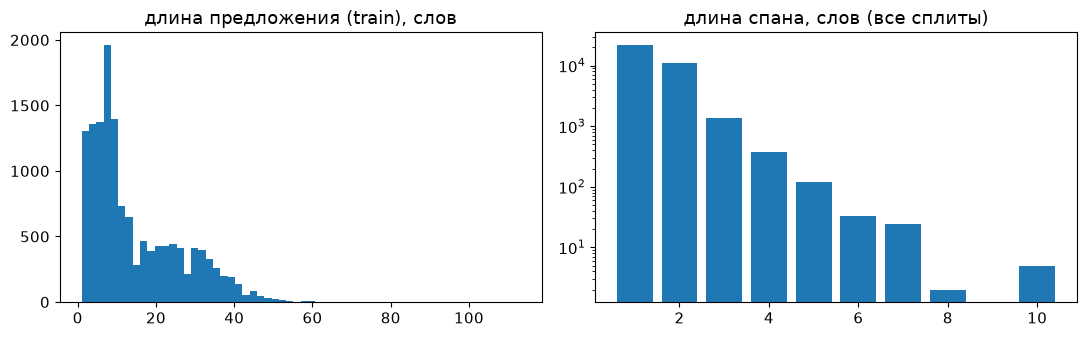

In [14]:
def span_stats(split):
    types, lengths = collections.Counter(), collections.Counter()
    for tags in raw[split]['ner_tags']:
        for s, e, t in bio_to_spans_simple([LABEL_NAMES[i] for i in tags]):
            types[t] += 1
            lengths[e - s] += 1
    return types, lengths


def bio_to_spans_simple(tags):   # быстрая версия для статистики (полноценная bio_to_spans - в 2.2)
    spans, cur = [], None
    for i, t in enumerate(tags + ['O']):
        if cur and (t == 'O' or t.startswith('B-') or t[2:] != cur[2]):
            spans.append(tuple(cur)); cur = None
        if t != 'O':
            if cur is None:
                cur = [i, i + 1, t[2:]]
            else:
                cur[1] = i + 1
    return spans


all_types = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
print(f'{"split":<12}{"sent":>7}{"words":>8}' + ''.join(f'{t:>7}' for t in all_types) + f'{"all":>7}')
span_len_all, sent_len = collections.Counter(), {}
for split in ['train', 'validation', 'test']:
    types, lengths = span_stats(split)
    span_len_all.update(lengths)
    sent_len[split] = [len(ws) for ws in raw[split]['tokens']]
    print(f'{split:<12}{len(raw[split]):>7}{sum(sent_len[split]):>8}' + ''.join(f'{types[t]:>7}' for t in all_types)
          + f'{sum(types.values()):>7}')
print('длины спанов в словах (все сплиты):', dict(sorted(span_len_all.items())))
for split, ls in sent_len.items():
    print(f'{split}: длина предложения в словах - среднее {np.mean(ls):.1f}, медиана {np.median(ls):.0f}, '
          f'95% {np.percentile(ls, 95):.0f}, max {max(ls)}')
o_share = np.mean([t == 0 for tags in raw['train']['ner_tags'] for t in tags])
print(f'доля слов с тегом O в train: {o_share:.1%}')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(sent_len['train'], bins=60)
ax[0].set_title('длина предложения (train), слов')
ks = sorted(span_len_all)
ax[1].bar(ks, [span_len_all[k] for k in ks])
ax[1].set_yscale('log')
ax[1].set_title('длина спана, слов (все сплиты)')
plt.tight_layout()
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** CoNLL-2003 (Tjong Kim Sang & De Meulder, 2003): новости агентства Reuters (корпус RCV1, 1996-1997), размечены **вручную** в Университете Антверпена. Лицензия в карточке `other`: разметка свободна для исследований, тексты Reuters - по исследовательскому соглашению. Четыре типа: PER, ORG, LOC, MISC, сплиты train/validation/test = 14 041 / 3 250 / 3 453 предложений (203k / 51k / 46k слов). Сущностей: train LOC 7140, PER 6600, ORG 6321, **MISC 3438** (самый редкий, ~15%); validation 5942, test 5648. Спаны короткие: 63% из 1 слова, 31% из 2, длиннее 3 слов - <2%. Предложения в среднем 14.5 слова (медиана 10, 95-й перцентиль 37, максимум 124), 83% слов имеют тег `O`. Особенности: много коротких строк-заголовков КАПСОМ и таблиц спортивных результатов («CRICKET - LEICESTERSHIRE TAKE OVER AT TOP»), где регистр не помогает, а контекста почти нет; MISC - неоднородный класс (национальности, события, названия); test взят из более позднего периода, чем train/validation, поэтому на test ожидается заметно ниже F1; в разметке известен шум (в CoNLL++ исправили ошибки примерно в 5% предложений test).

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans, cur = [], None
    for i, tag in enumerate(tags):
        if tag == 'O':
            if cur is not None:
                spans.append(tuple(cur))
                cur = None
            continue
        prefix, typ = tag[:2], tag[2:]
        if prefix == 'I-' and cur is not None and cur[2] == typ:
            cur[1] = i + 1                       # продолжение спана того же типа
        else:                                    # B-X или I-X без подходящего начала - новый спан
            if cur is not None:
                spans.append(tuple(cur))
            cur = [i, i + 1, typ]
    if cur is not None:
        spans.append(tuple(cur))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, typ in spans:
        tags[start] = 'B-' + typ
        for i in range(start + 1, end):
            tags[i] = 'I-' + typ
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels, prev = [], None
    for w in word_ids:
        if w is None:
            labels.append(-100)
        elif w != prev:                          # первый сабворд слова
            labels.append(word_labels[w])
        elif b_to_i is None:                     # продолжение слова - игнорируется в loss
            labels.append(-100)
        else:                                    # продолжение слова: B-X -> I-X
            labels.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# CoNLL-2003 уже в BIO: экспорт в спаны JSON, чтение обратно, BIO, сравнение с исходным
Path('data').mkdir(exist_ok=True)
for split in ['train', 'validation', 'test']:
    path = Path('data') / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as f:
        for ex in raw[split]:
            tags = [LABEL_NAMES[i] for i in ex['ner_tags']]
            f.write(json.dumps({'tokens': ex['tokens'],
                                'spans': [list(s) for s in bio_to_spans(tags)]}, ensure_ascii=False) + '\n')
    n_same_tags = n_same_spans = n_i_without_b = n = 0
    with path.open(encoding='utf-8') as f:
        for line, ex in zip(f, raw[split]):
            rec = json.loads(line)
            back = spans_to_bio([tuple(s) for s in rec['spans']], len(rec['tokens']))
            orig = [LABEL_NAMES[i] for i in ex['ner_tags']]
            assert rec['tokens'] == ex['tokens']
            n += 1
            n_same_tags += back == orig
            n_same_spans += bio_to_spans(back) == bio_to_spans(orig)
            n_i_without_b += any(t.startswith('I-') and (i == 0 or orig[i - 1][2:] != t[2:] or orig[i - 1] == 'O')
                                 for i, t in enumerate(orig))
    print(f'{split:<11} {n} предл.: BIO совпал дословно {n_same_tags}, спаны совпали {n_same_spans}, '
          f'предложений с I-X без B-X {n_i_without_b}')
    assert n_same_spans == n
print(open(Path('data') / 'validation_spans.jsonl', encoding='utf-8').readline()[:300])

train       14041 предл.: BIO совпал дословно 14041, спаны совпали 14041, предложений с I-X без B-X 0


validation  3250 предл.: BIO совпал дословно 3250, спаны совпали 3250, предложений с I-X без B-X 0


test        3453 предл.: BIO совпал дословно 3453, спаны совпали 3453, предложений с I-X без B-X 0
{"tokens": ["CRICKET", "-", "LEICESTERSHIRE", "TAKE", "OVER", "AT", "TOP", "AFTER", "INNINGS", "VICTORY", "."], "spans": [[2, 3, "ORG"]]}



In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/14041 [00:00<?, ? examples/s]

Map:   0%|          | 0/3250 [00:00<?, ? examples/s]

Map:   0%|          | 0/3453 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 14041
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3250
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 3453
    })
})
ENTITY_TYPES ['LOC', 'MISC', 'ORG', 'PER']


train: проверено 14040 предложений, обрезано по MAX_LENGTH 1, слов без сабвордов или за обрезкой 28
[CLS]            None  -100
EU                  0  B-ORG
rejects             1  O
German              2  B-MISC
call                3  O
to                  4  O
boycott             5  O
British             6  B-MISC
la                  7  O
##mb                7  -100
.                   8  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Метка ставится только на первый сабворд, чтобы каждое слово давало в loss ровно один пример: иначе длинные слова (например, редкие фамилии из 5 сабвордов) получали бы больший вес, а предсказание по слову все равно берется с первого сабворда. `-100` - это `ignore_index` у `CrossEntropyLoss`: такие позиции (спецтокены, продолжения слов, паддинг) не дают ни loss, ни градиента. В train по `MAX_LENGTH = 128` обрезано 1 предложение из 14 041, потеряно 28 слов; слов без сабвордов нет (BERT-токенизатор любое слово превращает хотя бы в `[UNK]`). На validation/test обрезанные слова получат `O` - влияние на F1 пренебрежимо (<0.01% слов). При конвертации проблем не нашлось: датасет уже в валидном BIO (0 предложений с `I-X` без `B-X`), круг «BIO -> спаны JSON -> BIO» совпал дословно для всех 20 744 предложений, вложенных и пересекающихся спанов в CoNLL нет. Строки `-DOCSTART-` фильтр отбрасывает, но в parquet-версии их уже нет.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            counts[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}   # ваш код: baseline['majority'] и baseline['random_head'] - словари entity_scores
train_tags = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
maj_pred = [predict_majority(tagger, ws) for ws in val_tokens]
baseline['majority'] = entity_scores(val_gold, maj_pred)
unk = np.mean([w not in tagger for ws in val_tokens for w in ws])
unk_ent = np.mean([w not in tagger for ws, gs in zip(val_tokens, val_gold) for w, g in zip(ws, gs) if g != 'O'])
print(f'словарь: {len(tagger)} слов; незнакомых слов в validation {unk:.1%}, среди слов сущностей {unk_ent:.1%}')

set_seed(SEED)
random_model = make_model()
rnd_pred = predict_word_tags(random_model, val_tokens)
baseline['random_head'] = entity_scores(val_gold, rnd_pred)
print('теги случайной головы:', collections.Counter(t for tags in rnd_pred for t in tags).most_common())
random_model = random_model.cpu()
del random_model
for name, sc in baseline.items():
    print(f'{name:<12}', {k: round(v, 4) for k, v in sc.items() if isinstance(v, float)})

словарь: 23623 слов; незнакомых слов в validation 8.4%, среди слов сущностей 20.4%


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

теги случайной головы: [('B-ORG', 21915), ('B-MISC', 7989), ('B-PER', 7424), ('I-MISC', 4519), ('B-LOC', 3455), ('I-LOC', 2470), ('I-PER', 1559), ('O', 1393), ('I-ORG', 638)]


majority     {'f1_micro': np.float64(0.6536), 'f1_macro': np.float64(0.6523), 'precision': np.float64(0.6718), 'recall': np.float64(0.6365)}
random_head  {'f1_micro': np.float64(0.0356), 'f1_macro': np.float64(0.0369), 'precision': np.float64(0.02), 'recall': np.float64(0.16)}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарный бейзлайн на validation: entity F1 = **0.654** (P 0.672, R 0.637), token F1 = 0.708. Это много для такого простого метода, потому что в новостях сущности часто повторяются (страны, города, команды, политики): только 20.4% слов сущностей validation не встречались в train. Он не может разрешить многозначность (Washington - PER или LOC), не видит контекст и ломает многословные спаны, если одно слово незнакомое. Энкодер со случайной головой дает F1 **0.036** (P 0.020, R 0.160): он ставит `B-ORG` 21 915 словам из 51 362, а `O` - только 1 393. Энкодер предобучен и признаки у него хорошие, но голова `Linear(768, 9)` инициализирована случайно, и связь «признак -> номер тега» произвольная: модель даже не знает, какой выход означает `O`. Без дообучения головы предобученный энкодер для NER бесполезен.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 3e-5          # bert-base: стандартный диапазон 2e-5 - 5e-5 (Devlin et al., 2019)
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:   # учится только голова classifier
        head_names = {n for n, _ in model.named_parameters() if n.startswith('classifier')}
        for n, p in model.named_parameters():
            p.requires_grad = n in head_names
    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_every = max(1, total_steps // 20)   # ~20 точек на кривых
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=epochs, learning_rate=lr,
        per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
        warmup_steps=int(0.1 * total_steps), weight_decay=0.01, lr_scheduler_type='linear',
        eval_strategy='steps', eval_steps=log_every, logging_steps=log_every, save_strategy='no',
        fp16=torch.cuda.is_available(), seed=SEED, report_to='none', dataloader_num_workers=0,
        disable_tqdm=True)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    start = time.perf_counter()
    trainer.train()
    seconds = time.perf_counter() - start
    return trainer.state.log_history, seconds

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.357', 'grad_norm': '0.8274', 'learning_rate': '1.466e-05', 'epoch': '0.1481'}


{'eval_loss': '0.4309', 'eval_runtime': '2.142', 'eval_samples_per_second': '1518', 'eval_steps_per_second': '23.82', 'epoch': '0.1481'}


{'loss': '0.2179', 'grad_norm': '0.8095', 'learning_rate': '2.954e-05', 'epoch': '0.2961'}


{'eval_loss': '0.1091', 'eval_runtime': '2.427', 'eval_samples_per_second': '1339', 'eval_steps_per_second': '21.01', 'epoch': '0.2961'}


{'loss': '0.09054', 'grad_norm': '1.571', 'learning_rate': '2.841e-05', 'epoch': '0.4442'}


... (32 outputs left out)

{'eval_loss': '0.03469', 'eval_runtime': '2.507', 'eval_samples_per_second': '1296', 'eval_steps_per_second': '20.34', 'epoch': '2.813'}


{'loss': '0.01342', 'grad_norm': '0.4541', 'learning_rate': '4.553e-07', 'epoch': '2.961'}


{'eval_loss': '0.03416', 'eval_runtime': '2.448', 'eval_samples_per_second': '1328', 'eval_steps_per_second': '20.84', 'epoch': '2.961'}


{'eval_loss': '0.03416', 'eval_runtime': '2.465', 'eval_samples_per_second': '1319', 'eval_steps_per_second': '20.69', 'epoch': '3'}
{'train_runtime': '178.3', 'train_samples_per_second': '236.3', 'train_steps_per_second': '7.387', 'train_loss': '0.1068', 'epoch': '3'}
обучение: 178.6 c на NVIDIA GeForce RTX 4060 Laptop GPU, 14041 предложений, 3 эпох(а)


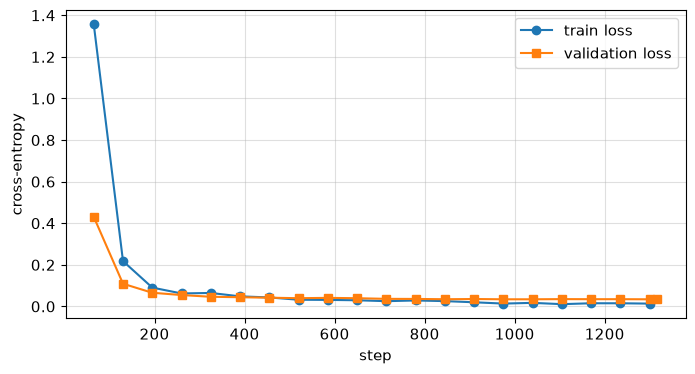

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** LR = 3e-5 - середина стандартного диапазона 2e-5 - 5e-5 для BERT-base; batch 32 влезает в 8 GB с fp16 и дает 439 шагов на эпоху; 3 эпохи - стандарт для CoNLL; linear warmup 10% и линейное затухание стабилизируют начало обучения, weight decay 0.01 - стандартная регуляризация из BERT; fp16 ускоряет обучение в ~2 раза. Кривые: train loss 1.36 -> 0.013, validation loss 0.431 -> 0.034, основное падение в первой половине первой эпохи. К концу 2-й эпохи validation loss выходит на плато (0.0345 на эпохе 1.93, 0.0342 на эпохе 3), а train loss продолжает падать (0.03 -> 0.013): разрыв растет, это начало переобучения, но eval loss не растет, поэтому 3 эпохи - разумно, а больше эпох почти ничего не даст. Обучение заняло **178.6 c** (1 317 шагов, 14 041 предложений × 3 эпохи) на NVIDIA GeForce RTX 4060 Laptop GPU.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = fp = fn = 0
    for g_sent, p_sent in zip(gold, pred):
        for g, p in zip(g_sent, p_sent):
            if p != 'O' and p == g:
                tp += 1
                continue
            if p != 'O':
                fp += 1
            if g != 'O':
                fn += 1
    if tp + fp + fn == 0:
        return 0.0
    return 2 * tp / (2 * tp + fp + fn)

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

final = {}       # ваш код: метрики на test: f1_micro, f1_macro, precision, recall, token_f1, per_type
val_pred = []    # предсказанные теги validation (список списков), нужны в 5.1
test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
by_split = {}
for split, gold_s, pred_s in [('validation', val_gold, val_pred), ('test', test_gold, test_pred)]:
    print(f'===== {split}')
    print(classification_report(gold_s, pred_s, digits=4, zero_division=0))
    sc = entity_scores(gold_s, pred_s)
    sc['token_f1'] = token_f1(gold_s, pred_s)
    rep = classification_report(gold_s, pred_s, output_dict=True, zero_division=0)
    sc['per_type'] = {t: {k: float(v) for k, v in rep[t].items()} for t in ENTITY_TYPES if t in rep}
    by_split[split] = sc
    print(f'entity F1 micro {sc["f1_micro"]:.4f}, macro {sc["f1_macro"]:.4f}, token F1 {sc["token_f1"]:.4f}')
final = dict(by_split['test'])
final['validation'] = {k: v for k, v in by_split['validation'].items()}
final['baseline_majority_token_f1_val'] = token_f1(val_gold, maj_pred)
print(f'token F1 словарного бейзлайна на validation: {final["baseline_majority_token_f1_val"]:.4f}')

===== validation


              precision    recall  f1-score   support

         LOC     0.9726    0.9646    0.9686      1837
        MISC     0.8700    0.9143    0.8916       922
         ORG     0.9162    0.9299    0.9230      1341
         PER     0.9718    0.9734    0.9726      1842

   micro avg     0.9430    0.9517    0.9473      5942
   macro avg     0.9326    0.9456    0.9389      5942
weighted avg     0.9437    0.9517    0.9476      5942



entity F1 micro 0.9473, macro 0.9389, token F1 0.9568
===== test


              precision    recall  f1-score   support

         LOC     0.9275    0.9353    0.9313      1668
        MISC     0.7756    0.8319    0.8027       702
         ORG     0.8785    0.9013    0.8897      1661
         PER     0.9609    0.9579    0.9594      1617

   micro avg     0.9025    0.9189    0.9106      5648
   macro avg     0.8856    0.9066    0.8958      5648
weighted avg     0.9038    0.9189    0.9112      5648



entity F1 micro 0.9106, macro 0.8958, token F1 0.9223
token F1 словарного бейзлайна на validation: 0.7075


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Хуже всего распознается **MISC**: F1 0.892 на validation и 0.803 на test (у PER 0.973 / 0.959, LOC 0.969 / 0.931, ORG 0.923 / 0.890). Это самый редкий тип (3 438 в train против 6-7 тысяч у остальных), самый разнородный (национальности, события, турниры, произведения), причем в основном это одиночные слова-прилагательные («German», «British»), которые легко спутать с LOC/ORG; длинные же MISC-спаны («U.S. Open Tennis Championships») модель часто обрезает. Средняя длина спана в train: ORG 1.59, PER 1.69, MISC 1.34, LOC 1.16 слова, так что дело не в длине. ORG на втором месте снизу из-за путаницы с LOC: спортивные команды названы по городам и странам. Micro F1 0.911 выше macro F1 0.896 на test, потому что micro усредняет по сущностям, где доминируют хорошо распознаваемые LOC/PER/ORG, а macro дает MISC такой же вес. Токенный F1 выше entity F1 (test 0.922 против 0.911, validation 0.957 против 0.947): при ошибке границы, например «[Test] and County Cricket Board», токенный F1 засчитывает правильные слова, а entity F1 не засчитывает спан целиком. У словарного бейзлайна разрыв больше (0.708 против 0.654), он чаще рвет многословные спаны. Пользователю NER нужны целые сущности (точное имя, название), поэтому ближе к практике entity F1. Падение с validation (0.947) на test (0.911) объясняется сдвигом во времени: test собран из новостей более позднего периода.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    gold_spans = [tuple(s) for s in gold_spans]
    pred_spans = [tuple(s) for s in pred_spans]

    def overlap(a, b):   # end не включается
        return a[0] < b[1] and b[0] < a[1]

    result = []
    for g in gold_spans:
        if g in pred_spans:
            result.append(('correct', g, g))
            continue
        same_type = [p for p in pred_spans if overlap(g, p) and p[2] == g[2]]
        if same_type:
            result.append(('boundary', g, same_type[0]))
            continue
        other_type = [p for p in pred_spans if overlap(g, p)]
        if other_type:
            result.append(('type', g, other_type[0]))
            continue
        result.append(('missed', g, None))
    for p in pred_spans:
        if not any(overlap(g, p) for g in gold_spans):
            result.append(('spurious', None, p))
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {}   # ваш код: {категория: число} на validation, затем доли и 5+ примеров
cat_counter = collections.Counter()
type_counter = collections.defaultdict(collections.Counter)   # категория -> тип истинной (или предсказанной) сущности
type_confusion = collections.Counter()
examples = collections.defaultdict(list)
for words, g_tags, p_tags in zip(val_tokens, val_gold, val_pred):
    for cat, g, p in categorize_errors(bio_to_spans(g_tags), bio_to_spans(p_tags)):
        cat_counter[cat] += 1
        type_counter[cat][(g or p)[2]] += 1
        if cat == 'type':
            type_confusion[(g[2], p[2])] += 1
        if cat != 'correct' and len(examples[cat]) < 3:
            examples[cat].append((words, g, p))
errors = {c: cat_counter[c] for c in ERROR_CATEGORIES}
n_err = sum(v for c, v in errors.items() if c != 'correct')
print('категории:', errors)
for c in ERROR_CATEGORIES[1:]:
    print(f'{c:<9} {errors[c]:>5}  {errors[c] / max(n_err, 1):6.1%} ошибок   по типам: {dict(type_counter[c])}')
print('ошибки типа (истинный -> предсказанный):', type_confusion.most_common(6))


def show_span(words, span):
    return 'None' if span is None else f'[{" ".join(words[span[0]:span[1]])}] {span[2]} {span[:2]}'


print()
for c in ERROR_CATEGORIES[1:]:
    for words, g, p in examples[c]:
        print(f'{c.upper():<9} | {" ".join(words)[:140]}')
        print(f'{"":<9} | gold: {show_span(words, g)}   pred: {show_span(words, p)}')

категории: {'correct': 5655, 'boundary': 79, 'type': 161, 'missed': 47, 'spurious': 70}
boundary     79   22.1% ошибок   по типам: {'ORG': 30, 'PER': 12, 'MISC': 31, 'LOC': 6}
type        161   45.1% ошибок   по типам: {'ORG': 49, 'LOC': 54, 'MISC': 32, 'PER': 26}
missed       47   13.2% ошибок   по типам: {'MISC': 16, 'ORG': 15, 'PER': 11, 'LOC': 5}
spurious     70   19.6% ошибок   по типам: {'MISC': 41, 'LOC': 5, 'PER': 8, 'ORG': 16}
ошибки типа (истинный -> предсказанный): [(('LOC', 'ORG'), 32), (('ORG', 'MISC'), 23), (('MISC', 'ORG'), 16), (('LOC', 'MISC'), 14), (('ORG', 'LOC'), 13), (('PER', 'ORG'), 13)]

BOUNDARY  | starting on May 13 next year , the Test and County Cricket Board
          | gold: [Test and County Cricket Board] ORG (8, 13)   pred: [Test] ORG (8, 9)
BOUNDARY  | May 15 v Duke of Norfolk 's XI ( at Arundel )
          | gold: [Duke of Norfolk 's XI] ORG (3, 8)   pred: [Duke of Norfolk 's] ORG (3, 7)
BOUNDARY  | Panamanian boxing legend Roberto " Hands of Stone " Du

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** На validation из 5 942 истинных спанов 5 655 найдены точно; ошибок 357: **type 161 (45%)**, boundary 79 (22%), spurious 70 (20%), missed 47 (13%). Самая частая - ошибка типа, в основном LOC -> ORG (32), ORG -> MISC (23), MISC -> ORG (16): это страны и города в спортивных новостях, где они обозначают команду («VOLGOGRAD», «PANAMA 'S ROBERTO DURAN»), и названия, которые можно отнести к организации или событию. Общее у примеров: заголовки КАПСОМ (нет признака регистра), очень короткие строки таблиц без контекста; boundary - длинные имена с кавычками и предлогами («Roberto " Hands of Stone " Duran», «Duke of Norfolk 's XI», «Test and County Cricket Board»); missed - слова с аффиксами («ex-England») и капс («ASHES», «ROTOR»); spurious - капитализированные нарицательные слова («INTERNATIONAL», «PASSPORT»). Часть ошибок типа - скорее спорная разметка: команда, названная по городу или стране, в похожих предложениях размечена то как LOC, то как ORG, и модель здесь штрафуют за неоднозначность самих данных; известно, что в CoNLL-2003 test ~5% предложений содержат ошибки разметки. Чтобы уменьшить ошибки типа, я бы давал модели контекст документа (соседние предложения из той же новости, где видно, что речь о матче), добавил аугментацию КАПСОМ и попробовал более сильную модель (roberta-large / deberta-v3).

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
ablation = {}   # ваш код


def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


full_trainable = sum(p.numel() for p in model.parameters())   # в 4.1 обучались все параметры
set_seed(SEED)
frozen_model = make_model()
frozen_history, frozen_seconds = train_ner(frozen_model, tokenized['train'], tokenized['validation'],
                                           freeze_encoder=True, out_dir='runs/freeze')
RUN_TIMES['train_freeze_sec'] = frozen_seconds
frozen_pred = predict_word_tags(frozen_model, val_tokens)


def last_eval_loss(hist):
    return [h['eval_loss'] for h in hist if 'eval_loss' in h][-1]


ablation = dict(
    setting=ABLATION, split='validation', lr=LR, epochs=EPOCHS,
    full=dict(**entity_scores(val_gold, val_pred), token_f1=token_f1(val_gold, val_pred),
              train_sec=RUN_TIMES['train_main_sec'], trainable_params=full_trainable,
              eval_loss=last_eval_loss(history)),
    freeze=dict(**entity_scores(val_gold, frozen_pred), token_f1=token_f1(val_gold, frozen_pred),
                train_sec=frozen_seconds, trainable_params=n_trainable(frozen_model),
                eval_loss=last_eval_loss(frozen_history)))
print(f'{"":<8}{"F1 micro":>10}{"F1 macro":>10}{"tok F1":>9}{"eval loss":>11}{"sec":>8}{"trainable":>13}')
for k in ['full', 'freeze']:
    a = ablation[k]
    print(f'{k:<8}{a["f1_micro"]:>10.4f}{a["f1_macro"]:>10.4f}{a["token_f1"]:>9.4f}{a["eval_loss"]:>11.4f}'
          f'{a["train_sec"]:>8.1f}{a["trainable_params"]:>13,}')
print('теги замороженной модели:', collections.Counter(t for tags in frozen_pred for t in tags).most_common(5))
frozen_model = frozen_model.cpu()
del frozen_model

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.366', 'grad_norm': '7.75', 'learning_rate': '1.466e-05', 'epoch': '0.1481'}


{'eval_loss': '2.287', 'eval_runtime': '2.484', 'eval_samples_per_second': '1308', 'eval_steps_per_second': '20.53', 'epoch': '0.1481'}


{'loss': '2.228', 'grad_norm': '7.004', 'learning_rate': '2.954e-05', 'epoch': '0.2961'}


{'eval_loss': '2.074', 'eval_runtime': '2.474', 'eval_samples_per_second': '1314', 'eval_steps_per_second': '20.61', 'epoch': '0.2961'}


{'loss': '1.978', 'grad_norm': '6.92', 'learning_rate': '2.841e-05', 'epoch': '0.4442'}


... (33 outputs left out)

{'loss': '0.7062', 'grad_norm': '1.36', 'learning_rate': '4.553e-07', 'epoch': '2.961'}


{'eval_loss': '0.7095', 'eval_runtime': '2.166', 'eval_samples_per_second': '1500', 'eval_steps_per_second': '23.55', 'epoch': '2.961'}


{'eval_loss': '0.7094', 'eval_runtime': '2.202', 'eval_samples_per_second': '1476', 'eval_steps_per_second': '23.16', 'epoch': '3'}
{'train_runtime': '87.79', 'train_samples_per_second': '479.8', 'train_steps_per_second': '15', 'train_loss': '1.16', 'epoch': '3'}


          F1 micro  F1 macro   tok F1  eval loss     sec    trainable
full        0.9473    0.9389   0.9568     0.0342   178.6  107,726,601
freeze      0.0010    0.0008   0.0055     0.7094    88.2        6,921
теги замороженной модели: [('O', 51312), ('B-PER', 29), ('I-PER', 15), ('B-ORG', 5), ('B-LOC', 1)]


**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Замороженный энкодер (учится только голова, 6 921 параметр против 107.7M) при тех же гиперпараметрах дал на validation entity F1 **0.001** против **0.947** у полного дообучения; eval loss 0.709 против 0.034; время 88 c против 179 c. Замороженная модель почти все слова помечает `O` (51 312 из 51 362): за 1 317 шагов с LR = 3e-5 линейная голова успела выучить только априорную частоту тега `O` (83% слов), но не разделение типов. Время сократилось лишь вдвое: прямой проход через весь энкодер остается, экономится только backward и обновление весов. Вывод «замороженные признаки BERT плохи» отсюда делать нельзя: LR 3e-5 подобран для полного дообучения, а для линейной пробы нужен LR 1e-3 - 1e-2 и больше эпох. Следующим шагом я бы подобрал LR для замороженной головы на validation, повторил оба варианта на 3 seed-ах и сравнил с абляцией `all_subwords`.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Дообученный `bert-base-cased` на CoNLL-2003 дал entity F1 **0.911** на test (micro; macro 0.896, token F1 0.922) и 0.947 на validation - на ~1.3 пункта ниже статьи BERT (92.4 на test, но там использовался контекст документа, а у нас - отдельные предложения), за 179 c обучения на RTX 4060 Laptop. Это намного выше словарного бейзлайна (0.654 на validation) и случайной головы (0.036): предобученный энкодер сам по себе не решает задачу, но после 3 эпох дообучения переносит знания о языке на NER. Лучше всего распознаются PER и LOC (0.96 / 0.93 на test), хуже всего MISC (0.80) - редкий и разнородный класс. Половина ошибок - ошибки типа (LOC/ORG в спортивных новостях), пятая часть - границы длинных имен. Абляция с замороженным энкодером при том же LR не обучилась (F1 0.001), т.е. при таком бюджете нужно дообучать весь энкодер. Главные ограничения: один seed и одна модель; разрыв validation/test (~3.7 пункта) из-за сдвига во времени; шум разметки CoNLL; предложения без документного контекста; модель сильно зависит от регистра (F1 падает до 0.28 на тексте в нижнем регистре, см. 6.3). Дальше я бы добавил контекст документа, попробовал RoBERTa/DeBERTa, усреднил по нескольким seed-ам и добавил аугментацию регистра.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google-bert/bert-base-cased", "revision": "cd5ef92a9fb2f889e972770a36d4ed042daf221e", "dataset": "eriktks/conll2003", "classes": ["LOC", "MISC", "ORG", "PER"], "n_train": 14041, "n_val": 3250, "n_test": 3453, "params_total": 107726601, "ablation": {"setting": "freeze", "split": "validation", "lr": 3e-05, "epochs": 3, "full": {"f1_micro": 0.9473155205628613, "f1_macro": 0.93894720960582, "precision": 0.9429714857428715, "recall": 0.9516997643890945, "token_f1": 0.9568499912886927, "train_sec": 178.57314249999945, "trainable_params": 107726601, "eval_loss": 0.034157514
final F1 micro 0.9106


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [30]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Бонус 6.1 не выполнялся.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Бонус 6.2 не выполнялся.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    shift_rng = random.Random(SEED)

    def add_typos(word, rng, p=0.3):   # перестановка двух соседних букв в слове длиной 4+ с вероятностью p
        if len(word) < 4 or not word.isalpha() or rng.random() > p:
            return word
        i = rng.randrange(len(word) - 1)
        return word[:i] + word[i + 1] + word[i] + word[i + 2:]

    corruptions = {
        'clean': lambda ws: ws,
        'lower': lambda ws: [w.lower() for w in ws],
        'upper': lambda ws: [w.upper() for w in ws],
        'typos30%': lambda ws: [add_typos(w, shift_rng) for w in ws],
    }
    shift = {}
    for name, fn in corruptions.items():
        corrupted = [fn(ws) for ws in val_tokens]
        pred_c = predict_word_tags(model, corrupted)
        sc = entity_scores(val_gold, pred_c)
        maj_c = entity_scores(val_gold, [predict_majority(tagger, ws) for ws in corrupted])['f1_micro']
        n_sub = np.mean([len(tokenizer.tokenize(w)) for ws in corrupted[:500] for w in ws])
        shift[name] = dict(f1_micro=sc['f1_micro'], precision=sc['precision'], recall=sc['recall'],
                           majority_f1=maj_c, subwords_per_word=float(n_sub))
        print(f'{name:<9} F1 {sc["f1_micro"]:.4f}  P {sc["precision"]:.4f}  R {sc["recall"]:.4f}  '
              f'| словарь F1 {maj_c:.4f} | сабвордов на слово {n_sub:.2f}')
    print('пример:', corruptions['typos30%'](val_tokens[1]))
    (ARTIFACTS / 'shift.json').write_text(json.dumps(json_ready(shift), indent=2), encoding='utf-8')

clean     F1 0.9473  P 0.9430  R 0.9517  | словарь F1 0.6536 | сабвордов на слово 1.47


lower     F1 0.2791  P 0.6804  R 0.1755  | словарь F1 0.0155 | сабвордов на слово 1.58


upper     F1 0.4139  P 0.4281  R 0.4005  | словарь F1 0.3374 | сабвордов на слово 2.65


typos30%  F1 0.8329  P 0.8147  R 0.8519  | словарь F1 0.5097 | сабвордов на слово 1.69
пример: ['LONDON', '1996-08-30']


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** На validation (F1 0.947 на чистом тексте) сильнее всего роняет F1 **нижний регистр: 0.279** (P 0.680, R 0.176), затем верхний регистр 0.414, а опечатки (перестановка двух букв в 30% слов длиной от 4) - только до 0.833. Модель cased, и заглавная буква - главный признак имени собственного: в нижнем регистре модель почти перестает находить сущности (recall 0.18), хотя найденные еще часто верны (precision 0.68). В верхнем регистре признак тоже теряется, и слова режутся на в 1.8 раза больше сабвордов (2.65 на слово против 1.47), но в train есть заголовки КАПСОМ, поэтому падение меньше, чем у нижнего регистра. Опечатки портят только часть слов, а контекст и остальные сабворды сохраняются, поэтому падение умеренное; у словарного бейзлайна те же опечатки роняют F1 сильнее в относительных величинах (0.654 -> 0.510), так как он не знает измененных слов вовсе.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Бонус 6.4 не выполнялся.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean: порог 0 -> F1 0.9473; лучший порог 0.8 -> F1 0.9506 (P 0.9659, R 0.9357), прирост +0.0033


min: порог 0 -> F1 0.9473; лучший порог 0.7 -> F1 0.9503 (P 0.9611, R 0.9398), прирост +0.0030


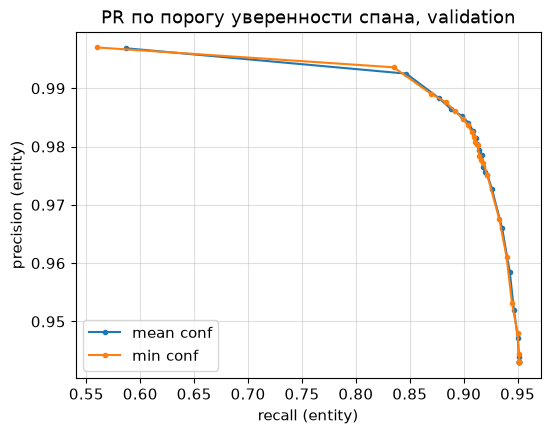

In [34]:
if '6.5' in BONUS_TASKS:
    tags_p, probs_p = predict_word_tags(model, val_tokens, return_probs=True)
    scored = []   # для каждого предложения: [(span, mean_conf, min_conf)]
    for tags, probs in zip(tags_p, probs_p):
        scored.append([(s, float(np.mean(probs[s[0]:s[1]])), float(np.min(probs[s[0]:s[1]])))
                       for s in bio_to_spans(tags)])

    def filtered(thr, agg):
        k = 1 if agg == 'mean' else 2
        return [spans_to_bio([x[0] for x in sent if x[k] >= thr], len(words))
                for sent, words in zip(scored, val_tokens)]

    thresholds = np.round(np.concatenate([np.linspace(0, 0.9, 10), np.linspace(0.92, 0.998, 14)]), 3)
    curves = {}
    for agg in ['mean', 'min']:
        curves[agg] = []
        for thr in thresholds:
            pr = filtered(thr, agg)
            curves[agg].append((float(thr), precision_score(val_gold, pr, zero_division=0),
                                recall_score(val_gold, pr, zero_division=0), f1_score(val_gold, pr, zero_division=0)))
        best = max(curves[agg], key=lambda r: r[3])
        print(f'{agg}: порог 0 -> F1 {curves[agg][0][3]:.4f}; лучший порог {best[0]} -> F1 {best[3]:.4f} '
              f'(P {best[1]:.4f}, R {best[2]:.4f}), прирост {best[3] - curves[agg][0][3]:+.4f}')
    plt.figure(figsize=(6, 4.5))
    for agg in curves:
        plt.plot([r[2] for r in curves[agg]], [r[1] for r in curves[agg]], 'o-', ms=3, label=f'{agg} conf')
    plt.xlabel('recall (entity)')
    plt.ylabel('precision (entity)')
    plt.title('PR по порогу уверенности спана, validation')
    plt.grid(True, alpha=0.4)
    plt.legend()
    plt.show()
    (ARTIFACTS / 'thresholds.json').write_text(json.dumps(curves, indent=2), encoding='utf-8')

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Лучший порог по средней уверенности спана - **0.8**: F1 0.9506 (P 0.966, R 0.936) против 0.9473 при пороге 0, т.е. **+0.0033**; по минимальной уверенности - 0.7: F1 0.9503 (+0.0030). Средняя уверенность сглаживает спан: одно сомнительное слово в длинном спане не убивает его; минимальная строже к длинным спанам (одно неуверенное слово отбрасывает весь спан), поэтому ее оптимальный порог ниже. Порог только выбрасывает спаны, а новых не добавляет: число верных спанов может лишь уменьшиться, поэтому recall при росте порога не растет (0.952 -> 0.936), а выигрыш идет только за счет precision. Прирост маленький, потому что модель уже хорошо откалибрована и ложных спанов мало; к тому же порог подобран на validation, и честнее проверить его на test.